# Inference and Validation

## Inputs:
- Trained models from [trained_models](trained_models).
- Gridded points (over grounded ice) from [data/YX_long_tensor.pt](data/YX_long_tensor.pt)
- Alongside [data/combined_mask.pt](data/combined_mask.pt) and [data/stricter_combined_mask.pt](data/stricter_combined_mask.pt) to go back from full grid inference to the valid set of these inference points on a 2D grid. 

## Outputs: 
- Visualisations
- BMB estimates

In [8]:
import numpy as np
import pandas as pd
import xarray as xr
import torch
import matplotlib.pyplot as plt

from models import FluxNet
from models import compute_divergence_field

from utils import spatial_subsample

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cpu


# Load

In [9]:
# Inference grid (but flattened) on Bedmap3 grid
XY_long_tensor = torch.load("data/XY_long_tensor.pt")

combined_mask = torch.load("data/combined_mask.pt")
stricter_combined_mask = torch.load("data/stricter_combined_mask.pt")

# Load model 0
# Initialise model architecture and load trained weights
model_0 = FluxNet().to(device)
model_0.load_state_dict(torch.load("trained_models/fluxnet_run_0_trained_model.pth"))
# Set model to evaluation mode (no compgraph)
model_0.eval()

FluxNet(
  (inp): Sequential(
    (0): Linear(in_features=2, out_features=256, bias=True)
    (1): SiLU()
  )
  (trunk): ModuleList(
    (0-5): 6 x _ResBlock(
      (lin1): Linear(in_features=256, out_features=256, bias=True)
      (lin2): Linear(in_features=256, out_features=256, bias=True)
      (act): SiLU()
    )
  )
  (head_df_psi): Linear(in_features=256, out_features=1, bias=True)
  (head_cf_phi): Linear(in_features=256, out_features=1, bias=True)
)

# 2. Evaluate on training data

How well did the model learn to represent the data it has been trained on? 

In [10]:
data = torch.load("data/flux_tensor.pt", weights_only = False)

# Subsample to reduce data - this is not random but sptially distributed on purpose
subset = spatial_subsample(data, n_cells = 400)
print(subset.shape)

# Or overwrite with full dataset but takes a while to run inference on the full dataset and to visualise
# subset = data

# Split into x and y to match model input and output
subset_x = subset[:, :2].to(device)
subset_y = subset[:, 2:].to(device)

torch.Size([8620, 4])


In [11]:
# grad must be on for divergence computation, so we set requires_grad = True
flux_prediction = model_0(subset_x.requires_grad_(True))

div_field = compute_divergence_field(
    mean_pred = flux_prediction, 
    x_grad = subset_x)

rmse_field = torch.sqrt(torch.mean((flux_prediction - subset_y) ** 2, dim = 1))
me_field = torch.mean((flux_prediction - subset_y), dim = 1)

me_field.mean().item()

0.004527666140347719

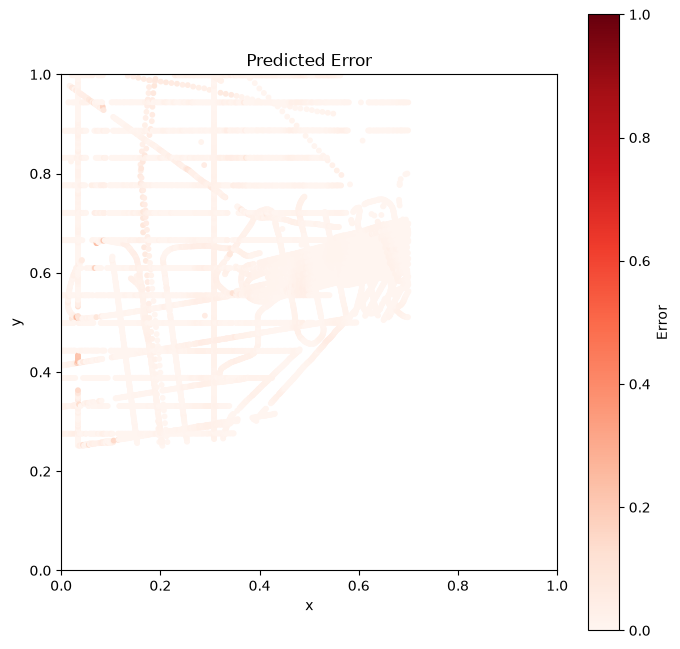

In [12]:
plt.figure(figsize = (8, 8))
plt.scatter(
    subset_x[:, 0].cpu().detach().numpy(), 
    subset_x[:, 1].cpu().detach().numpy(),
    c = me_field.cpu().detach().numpy(), 
    cmap = "Reds", 
    vmin = 0, vmax = 1,
    s = 10)
plt.colorbar(label = "Error")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Predicted Error")
plt.ylim(0, 1)
plt.xlim(0, 1)
plt.gca().set_aspect("equal")
plt.show()

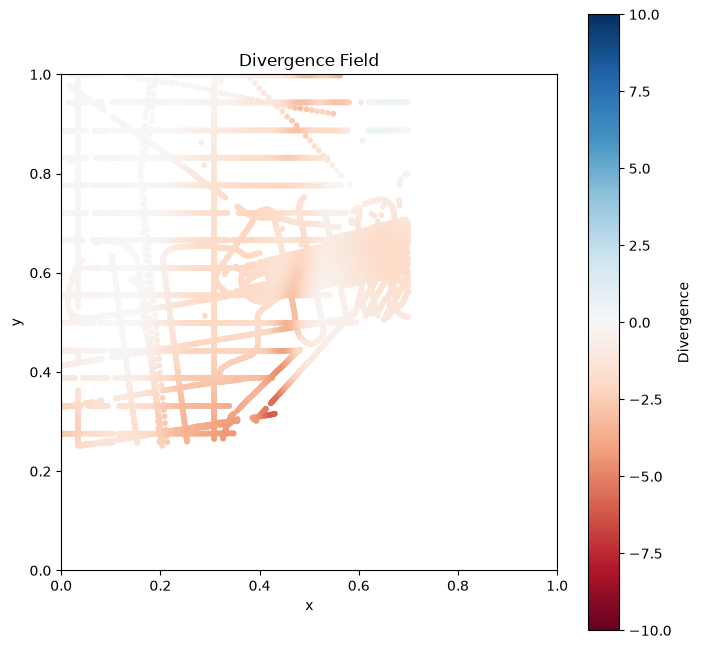

In [13]:
plt.figure(figsize = (8, 8))
plt.scatter(
    subset_x[:, 0].cpu().detach().numpy(), 
    subset_x[:, 1].cpu().detach().numpy(),
    c = div_field.cpu().detach().numpy(), 
    cmap = "RdBu", 
    vmin = -10, vmax = 10,
    s = 10)
plt.colorbar(label = "Divergence")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Divergence Field")
plt.ylim(0, 1)
plt.xlim(0, 1)
plt.gca().set_aspect("equal")
plt.show()

## 3. Inference over Bedmap grid

In [16]:
def run_inference_in_batches(model, XY_input_tensor, batch_size = 10000):
    """
    Run inference on a model in batches to avoid memory issues.
    """
    # Move model to device
    model = model.to(device)
    # Put in eval mode
    model.eval()

    # Move data to device (not too big for memory)
    XY_input_tensor = XY_input_tensor.to(device).to(torch.float32)
        
    # Total length
    N = XY_input_tensor.shape[0]

    # container for divergence batches
    div_container = torch.empty((N,), dtype = torch.float32, device = "cpu")
    
    for i in range(0, N, batch_size):

        # Define end index
        j = min(i + batch_size, N)

        print(f"Processing batch {i} to {j}...")

        # Subset batch
        XY_batch = XY_input_tensor[i : j , :]

        # Enable gradients
        XY_batch = XY_batch.requires_grad_(True)

        flux_predictions_batch = model(XY_batch)


        div_batch = compute_divergence_field(
            mean_pred = flux_predictions_batch, 
            x_grad = XY_batch)
        
        # For now only return divergence
        div_container[i:j] = div_batch.detach().cpu() 

        del div_batch
        del flux_predictions_batch
        torch.cuda.empty_cache()

    return div_container

In [ ]:
divergences_flat = run_inference_in_batches(model_0, XY_long_tensor, batch_size = 10_000)

print("Divergence shape:", divergences_flat.shape)

Processing batch 0 to 10000...
Processing batch 10000 to 20000...
Processing batch 20000 to 30000...
Processing batch 30000 to 40000...
Processing batch 40000 to 50000...
Processing batch 50000 to 60000...
Processing batch 60000 to 70000...
Processing batch 70000 to 80000...
Processing batch 80000 to 90000...
Processing batch 90000 to 100000...
Processing batch 100000 to 110000...
Processing batch 110000 to 120000...
Processing batch 120000 to 130000...
Processing batch 130000 to 140000...
Processing batch 140000 to 144000...


In [22]:
# Select mask
mask = stricter_combined_mask

# 1D -> 2D using shapes from the mask
divergences_2D = divergences_flat.unsqueeze(1).reshape(mask.shape[0], mask.shape[1])
print("Divergence field shape:", divergences_2D.shape)

# Mask out invalid values (where mask != 1) and replace with NaN
divergences_2D_valid = divergences_2D.masked_fill(mask != 1, float("nan"))

Divergence field shape: torch.Size([360, 400])


/var/folders/pv/_mchxpdj3tz_s_9735cr69pr0000gp/T/ipykernel_16858/397588568.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(XY_long_tensor[:, 0].reshape(mask.shape)).cpu().detach().numpy(),
/var/folders/pv/_mchxpdj3tz_s_9735cr69pr0000gp/T/ipykernel_16858/397588568.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(XY_long_tensor[:, 1].reshape(mask.shape)).cpu().detach().numpy(),


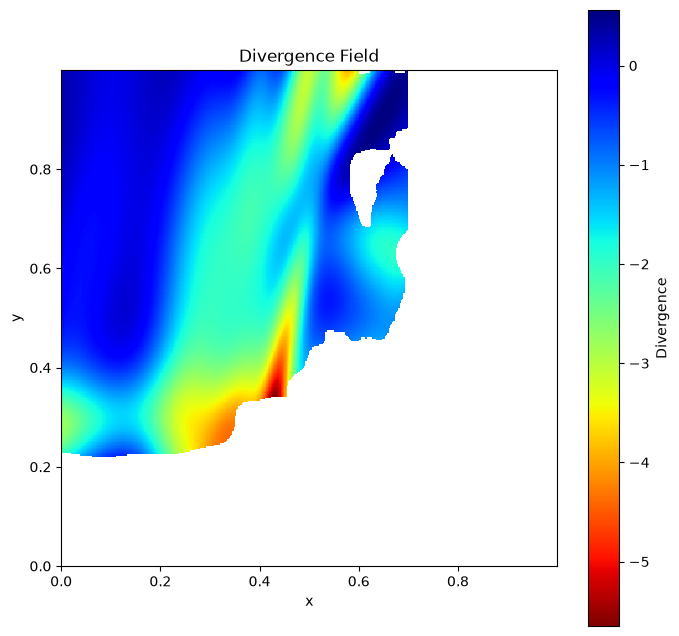

In [24]:
plt.figure(figsize = (8, 8))

plt.pcolormesh(
    # NOTE: 2D inputs
    # NOTE: Take original coords
    torch.tensor(XY_long_tensor[:, 0].reshape(mask.shape)).cpu().detach().numpy(), 
    torch.tensor(XY_long_tensor[:, 1].reshape(mask.shape)).cpu().detach().numpy(),
    divergences_2D_valid.cpu().detach().numpy(), 
    cmap = "jet_r", 
)
plt.colorbar(label = "Divergence")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Divergence Field")
plt.gca().set_aspect("equal")
plt.show()

4. Conversion back to physical units

- **dxy = 200_000** because the normalised range [0, 1] presents [0, 200_000 m] (200 km range) in real life.
- **flux_scale = 100_000** because we devided fluxes by 100_000 to acheve ~ 1 std i.e. var of flux in both directions.
- To rescale the div_field to physical units we do **div_phys = div_field * flux_scale / dxy**
- This simplifies to **dividing by 2** to get **m / year** units.

Prior:
- **dxy = 1_000_000** because the normalised range [0, 1] presents [0, 1_000_000 m] (1000 km range) in real life.
- **flux_scale = 100_000** because we devided fluxes by 100_000 to acheve ~ 1 std i.e. var of flux in both directions.
    - The mean ice thickness of 420 meters * 438 mean ice speed yields ice flux of 183_960 for example.
- To rescale the div_field to physical units we do **div_phys = div_field * flux_scale / dxy**
- This simplifies to **dividing by 10** to get **m / year** units.